# Preprocesamiento de los datos

**Proyecto:** Predicción de la asistencia actual al nivel superior en jóvenes de 18 a 24 años con secundario completo (EPH – INDEC)

**Autora:** Liliana Elizabeth Iñigo

**Materia:** Aprendizaje Automático

**Docente:** Nicolás Caballero

Esta notebook prepara el dataset para la etapa de modelado, siguiendo la secuencia de la Clase 3:

1. Definir qué se quiere predecir y qué información está disponible (variables de entrada **X** y objetivo **y**).
2. Aplicar reglas de calidad conocidas: recodificar categorías poco frecuentes y respuestas "Ns/Nr".
3. Separar entrenamiento y prueba.
4. Aprender **solo con el entrenamiento** los valores de imputación, las escalas y las categorías.
5. Aplicar esas mismas transformaciones a entrenamiento y prueba.
6. Revisar la matriz resultante.

**En esta notebook no se entrena ningún modelo.** El resultado son dos matrices de entrada listas para usar más adelante: una **escalada** (para métodos sensibles a la escala, como la regresión logística, KNN y SVM) y otra **sin escalar** (para árboles de decisión, que trabajan con umbrales).

Las decisiones se basan en lo observado en `2.0-lei-analisis-exploratorio.ipynb`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

pd.set_option("display.max_columns", 60)

datos = pd.read_csv("../data/processed/eph_jovenes_asistencia_superior.csv")
OBJETIVO = "asiste_superior"
datos.shape

(9665, 26)

## 1. Variables de entrada y variable objetivo

- **y:** `asiste_superior` (1 = asiste actualmente al nivel superior, 0 = no asiste).
- **Se excluyen de X:**
  - las columnas de identificación (`codusu`, `nro_hogar`, `componente`): identifican, no miden;
  - `ponderador`: es un factor de expansión de la encuesta, no una característica del joven;
  - `trimestre`: se usa solo para separar entrenamiento y prueba (sección 3);
  - `es_jefe_o_conyuge`: queda contenida en `parentesco_jefe`, que distingue jefe/a y cónyuge (sería información repetida);
  - `aglomerado`: tiene 32 categorías, varias con pocos casos, y repite la información de `region`, que agrupa los aglomerados. Se conserva `region`.
- Las variables con fuga de información (nivel educativo propio, preguntas educativas, becas, cuota alimentaria) ya fueron excluidas al construir el dataset (notebook 1.0).

In [2]:
# Clasificación de las columnas según su rol y su tipo (Clase 3, tabla de tipos de variables)
NUMERICAS = ["edad", "personas_hogar", "menores_10_hogar", "personas_por_ambiente"]
INGRESO = ["ingreso_resto_hogar_pc"]                        # numérica muy asimétrica: se transforma con logaritmo
BINARIAS = ["sexo_mujer", "ingresos_sin_respuesta", "ingreso_resto_cero"]   # ya son 0/1
NOMINALES = ["parentesco_jefe", "estado_civil", "cobertura_salud", "lugar_nacimiento", "condicion_actividad",
             "tipo_vivienda", "tenencia_vivienda", "jefe_nivel_educativo", "jefe_sexo",
             "jefe_condicion_actividad", "region"]
EXCLUIDAS = ["codusu", "nro_hogar", "componente", "ponderador", "trimestre", "es_jefe_o_conyuge", "aglomerado"]

## 2. Reglas de calidad conocidas: recodificación de categorías

Estas reglas no dependen de la distribución de los datos (son decisiones sobre el significado de cada código), por eso pueden aplicarse **antes** de separar entrenamiento y prueba sin generar fuga de información (Clase 3, sección 4.2).

Criterios:
- Los códigos se reemplazan por etiquetas con nombre, para que la matriz final sea legible.
- Las categorías con muy pocos casos (detectadas en el EDA) se agrupan con otras de significado parecido.
- Las respuestas "Ns/Nr" y "Sin entrevista individual" se convierten en **faltantes**, que después se imputan.
- Los datos del jefe/a de los jóvenes que son jefe/a o cónyuge se marcan como **"no aplica"**: no es un dato perdido, es un caso en que la variable no corresponde. Así queda como una categoría propia y no se imputa.
- **Ingreso del resto del hogar igual a 0:** en el EDA se vio que 675 jóvenes tienen este valor y que la mayoría vive solo (no hay "resto del hogar"). No es un ingreso bajo sino otra situación. Se crea el indicador `ingreso_resto_cero` y, para esos casos, el monto se deja vacío y se imputa como los demás faltantes; así el 0 no queda como un valor extremo después del logaritmo.
- El nivel educativo del jefe/a se trata como **nominal** (one-hot) y no como ordinal: incluye la categoría "no aplica", que no tiene un lugar en el orden, y así no se imponen distancias iguales entre niveles (Clase 3, sección 11.1).

In [3]:
RECODIFICACION = {
    "parentesco_jefe": {1: "jefe", 2: "conyuge", 3: "hijo", 5: "nieto", 4: "otro_familiar", 6: "otro_familiar",
                        7: "otro_familiar", 8: "otro_familiar", 9: "otro_familiar", 10: "no_familiar"},
    "estado_civil": {1: "unido_o_casado", 2: "unido_o_casado", 3: "separado_divorciado_viudo",
                     4: "separado_divorciado_viudo", 5: "soltero"},                  # 9 (Ns/Nr) -> faltante
    "cobertura_salud": {1: "obra_social_o_prepaga", 2: "obra_social_o_prepaga", 12: "obra_social_o_prepaga",
                        13: "obra_social_o_prepaga", 23: "obra_social_o_prepaga",
                        3: "solo_plan_publico", 4: "sin_cobertura"},                 # 9 (Ns/Nr) -> faltante
    "lugar_nacimiento": {1: "esta_localidad", 2: "otra_localidad_provincia", 3: "otra_provincia",
                         4: "otro_pais", 5: "otro_pais"},                            # 9 (Ns/Nr) -> faltante
    "condicion_actividad": {1: "ocupado", 2: "desocupado", 3: "inactivo"},            # 0 (sin entrevista) -> faltante
    "tipo_vivienda": {1: "casa", 2: "departamento", 3: "otro", 4: "otro", 5: "otro", 6: "otro"},
    "tenencia_vivienda": {1: "propietario", 2: "propietario", 3: "inquilino", 4: "otra_situacion",
                          5: "otra_situacion", 6: "otra_situacion", 7: "otra_situacion", 8: "otra_situacion",
                          9: "otra_situacion"},                                      # 0 (sin dato) -> faltante
    "jefe_nivel_educativo": {7: "sin_instruccion_o_primaria_incompleta", 1: "sin_instruccion_o_primaria_incompleta",
                             2: "primaria_completa", 3: "secundaria_incompleta", 4: "secundaria_completa",
                             5: "superior_incompleto", 6: "superior_completo"},
    "jefe_sexo": {1: "varon", 2: "mujer"},
    "jefe_condicion_actividad": {1: "ocupado", 2: "desocupado", 3: "inactivo"},       # 0 (sin entrevista) -> faltante
    "region": {1: "gran_buenos_aires", 40: "noroeste", 41: "noreste", 42: "cuyo", 43: "pampeana", 44: "patagonia"},
}

preparados = datos.copy()
for columna, mapa in RECODIFICACION.items():
    # Los códigos que no están en el mapa (Ns/Nr, sin entrevista, sin dato) quedan como faltantes (NaN)
    preparados[columna] = preparados[columna].map(mapa)

# Jóvenes jefe/a o cónyuge: los datos del jefe/a "no aplican" (categoría propia, no se imputa)
for columna in ["jefe_nivel_educativo", "jefe_sexo", "jefe_condicion_actividad"]:
    preparados.loc[preparados["es_jefe_o_conyuge"] == 1, columna] = "no_aplica"

# Variable binaria explícita (Clase 3, sección 11.3): 1 = mujer, 0 = varón
preparados["sexo_mujer"] = (preparados["sexo"] == 2).astype(int)

# Ingreso del resto del hogar = 0 (en su mayoría jóvenes que viven solos): indicador propio y monto vacío
preparados["ingreso_resto_cero"] = (preparados["ingreso_resto_hogar_pc"] == 0).astype(int)
preparados.loc[preparados["ingreso_resto_cero"] == 1, "ingreso_resto_hogar_pc"] = np.nan
print("Jóvenes con ingreso del resto del hogar = 0:", preparados["ingreso_resto_cero"].sum())

# Control: faltantes que dejó la recodificación (son los Ns/Nr y sin entrevista)
faltantes = preparados[NOMINALES].isna().sum()
faltantes[faltantes > 0].rename("faltantes después de recodificar").to_frame()

Jóvenes con ingreso del resto del hogar = 0: 675


,faltantes después de recodificar
estado_civil,1
cobertura_salud,31
lugar_nacimiento,6
condicion_actividad,23
tenencia_vivienda,4
jefe_condicion_actividad,11


In [4]:
# Frecuencias después de agrupar: ninguna categoría debería quedar con muy pocos casos sin justificación
for columna in ["parentesco_jefe", "cobertura_salud", "tipo_vivienda", "tenencia_vivienda", "jefe_nivel_educativo"]:
    print(f"\n{columna}")
    print(preparados[columna].value_counts(dropna=False).to_string())


parentesco_jefe
parentesco_jefe
hijo             6973
jefe             1005
otro_familiar     654
nieto             602
conyuge           332
no_familiar        99

cobertura_salud
cobertura_salud
obra_social_o_prepaga    5545
sin_cobertura            3959
solo_plan_publico         130
NaN                        31

tipo_vivienda
tipo_vivienda
casa            7679
departamento    1957
otro              29

tenencia_vivienda
tenencia_vivienda
propietario       6793
inquilino         1993
otra_situacion     875
NaN                  4

jefe_nivel_educativo
jefe_nivel_educativo
secundaria_completa                      2513
superior_completo                        1690
primaria_completa                        1486
no_aplica                                1337
secundaria_incompleta                    1289
superior_incompleto                       956
sin_instruccion_o_primaria_incompleta     394


**Lectura:** la recodificación dejó solo unos pocos faltantes (las respuestas "Ns/Nr" y las entrevistas individuales no realizadas) y categorías con suficientes casos. El grupo `tipo_vivienda = otro` sigue siendo chico (29 casos), pero reúne situaciones parecidas (piezas, locales) y se conserva como una categoría.

## 3. Separación en entrenamiento y prueba

Se reservan datos de prueba que no participan de la preparación, para poder evaluar más adelante con observaciones no usadas para aprender.

**Criterio: partición temporal, no aleatoria.** Se entrena con los trimestres de **2025** y se reserva el **1.er trimestre de 2026** como prueba. La Clase 3 advierte que una partición aleatoria no siempre es adecuada cuando los datos tienen tiempo o personas repetidas. Esta partición, además:

- simula el segundo tiempo del planteo: aprender con datos pasados y comprobar con datos más nuevos que publica el INDEC;
- evita que la misma persona quede en los dos conjuntos: el dataset tiene una sola fila por persona (la observación más reciente), así que quien aparece en 1T 2026 no está en 2025.

In [5]:
es_prueba = preparados["trimestre"] == "2026T1"
entrenamiento = preparados[~es_prueba]
prueba = preparados[es_prueba]

COLUMNAS_X = NUMERICAS + INGRESO + BINARIAS + NOMINALES
X_train, y_train = entrenamiento[COLUMNAS_X], entrenamiento[OBJETIVO]
X_test, y_test = prueba[COLUMNAS_X], prueba[OBJETIVO]

# Control de la partición: tamaños, proporción de clases y que no haya personas en ambos conjuntos
clave = ["codusu", "nro_hogar", "componente"]
compartidas = entrenamiento[clave].merge(prueba[clave]).shape[0]
pd.DataFrame({
    "personas": [len(X_train), len(X_test)],
    "% del total": [round(len(X_train) / len(preparados) * 100, 1), round(len(X_test) / len(preparados) * 100, 1)],
    "% que asiste": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)],
}, index=["Entrenamiento (2T a 4T 2025)", "Prueba (1T 2026)"]).assign(**{"personas en ambos conjuntos": [compartidas, compartidas]})

,personas,% del total,% que asiste,personas en ambos conjuntos
Entrenamiento (2T a 4T 2025),6168,63.8,55.6,0
Prueba (1T 2026),3497,36.2,53.5,0


**Lectura:** el entrenamiento tiene 6.168 jóvenes (64 %) y la prueba 3.497 (36 %). La proporción de clases es parecida en los dos (56 % y 54 % asiste), así que la partición temporal no introduce un desbalance importante. No hay personas compartidas entre los dos conjuntos.

## 4. Transformaciones por tipo de variable

Se arma un `ColumnTransformer` (Clase 3, sección 14) que aplica un tratamiento distinto a cada grupo de columnas. Todos los parámetros (medianas, medias, desvíos, categorías) se aprenden con `fit` **solo sobre el entrenamiento**.

| Grupo | Columnas | Pasos | Por qué |
|---|---|---|---|
| Numéricas | edad, personas_hogar, menores_10_hogar, personas_por_ambiente | Imputación por **mediana** → **estandarización** | La mediana es poco sensible a los valores extremos de los conteos; la estandarización evita que una variable domine por su unidad en métodos basados en distancias |
| Ingreso | ingreso_resto_hogar_pc | **log(1 + x)** → imputación por **mediana** → **estandarización** | Es muy asimétrico (asimetría ≈ 12) y con extremos válidos; el logaritmo lo vuelve casi simétrico |
| Binarias | sexo_mujer, ingresos_sin_respuesta, ingreso_resto_cero | Sin cambios | Ya son 0/1. Los dos indicadores de ingreso conservan la información de por qué el monto fue imputado |
| Nominales | parentesco, estado civil, cobertura, lugar de nacimiento, condición de actividad, vivienda, tenencia, datos del jefe/a, región | Imputación por **categoría más frecuente** → **one-hot** | One-hot no impone un orden entre categorías. Los faltantes son muy pocos (Ns/Nr), por eso alcanza con la moda |

**Sobre la imputación del ingreso:** falta en el 28,8 % de los casos porque el hogar no respondió, y además se dejó vacío para los 675 casos con valor 0. Se completa con la mediana del entrenamiento para no perder esas filas, pero **imputar no recupera el dato verdadero**: por eso se mantienen `ingresos_sin_respuesta` e `ingreso_resto_cero`, que permiten distinguir los valores imputados. En el EDA se vio que el faltante se asocia levemente con la respuesta (52,7 % frente a 55,7 % de asistencia), lo que refuerza conservar el indicador.

Se preparan **dos variantes**, como en la Clase 3: con escalado y sin escalado (para árboles, que no lo necesitan).

In [6]:
def armar_preprocesador(escalar=True):
    # Devuelve el ColumnTransformer; con escalar=False omite la estandarización (variante para árboles)
    escalador = [("estandarizar", StandardScaler())] if escalar else []
    numericas = Pipeline([("imputar", SimpleImputer(strategy="median"))] + escalador)
    ingreso = Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                        ("imputar", SimpleImputer(strategy="median"))] + escalador)
    nominales = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([
        ("numericas", numericas, NUMERICAS),
        ("ingreso", ingreso, INGRESO),
        ("binarias", "passthrough", BINARIAS),
        ("nominales", nominales, NOMINALES),
    ], verbose_feature_names_out=False)

# Variante escalada: se ajusta (fit) con entrenamiento y se aplica (transform) a ambos conjuntos
preprocesador_escalado = armar_preprocesador(escalar=True)
X_train_esc = preprocesador_escalado.fit_transform(X_train)
X_test_esc = preprocesador_escalado.transform(X_test)

# Variante sin escalar (para árboles)
preprocesador_sin_escalar = armar_preprocesador(escalar=False)
X_train_sin = preprocesador_sin_escalar.fit_transform(X_train)
X_test_sin = preprocesador_sin_escalar.transform(X_test)

columnas_salida = preprocesador_escalado.get_feature_names_out()
X_train_esc = pd.DataFrame(X_train_esc, columns=columnas_salida, index=X_train.index)
X_test_esc = pd.DataFrame(X_test_esc, columns=columnas_salida, index=X_test.index)
X_train_sin = pd.DataFrame(X_train_sin, columns=preprocesador_sin_escalar.get_feature_names_out(), index=X_train.index)
X_test_sin = pd.DataFrame(X_test_sin, columns=preprocesador_sin_escalar.get_feature_names_out(), index=X_test.index)

print(f"Columnas de entrada originales: {len(COLUMNAS_X)}  →  columnas después de one-hot: {len(columnas_salida)}")
print("Entrenamiento:", X_train_esc.shape, "· Prueba:", X_test_esc.shape)

Columnas de entrada originales: 19  →  columnas después de one-hot: 53
Entrenamiento: (6168, 53) · Prueba: (3497, 53)


In [7]:
# Valores aprendidos con el entrenamiento (se reutilizan tal cual en la prueba)
imputador_ingreso = preprocesador_escalado.named_transformers_["ingreso"].named_steps["imputar"]
escala_numericas = preprocesador_escalado.named_transformers_["numericas"].named_steps["estandarizar"]
print(f"Mediana aprendida del ingreso (en log(1+x)): {imputador_ingreso.statistics_[0]:.2f} "
      f"≈ {np.expm1(imputador_ingreso.statistics_[0]):,.0f} pesos")
pd.DataFrame({"media aprendida": escala_numericas.mean_, "desvío aprendido": np.sqrt(escala_numericas.var_)},
             index=NUMERICAS).round(2)

Mediana aprendida del ingreso (en log(1+x)): 13.07 ≈ 472,250 pesos


,media aprendida,desvío aprendido
edad,21.24,1.92
personas_hogar,3.96,1.81
menores_10_hogar,0.26,0.60
personas_por_ambiente,1.35,0.73


## 5. Revisión de la matriz resultante

Controles (Clase 3, paso 6):
- que no queden faltantes;
- que las numéricas escaladas tengan media ≈ 0 y desvío ≈ 1 **en entrenamiento** (en prueba no tiene por qué cumplirse exactamente, porque se usan la media y el desvío del entrenamiento);
- que las columnas one-hot sean 0/1 y no se escalen.

In [8]:
print("Faltantes en la matriz de entrenamiento:", int(X_train_esc.isna().sum().sum()))
print("Faltantes en la matriz de prueba:", int(X_test_esc.isna().sum().sum()))

escaladas = NUMERICAS + INGRESO
pd.DataFrame({
    "media entrenamiento": X_train_esc[escaladas].mean(),
    "desvío entrenamiento": X_train_esc[escaladas].std(ddof=0),
    "media prueba": X_test_esc[escaladas].mean(),
    "desvío prueba": X_test_esc[escaladas].std(ddof=0),
}).round(3)

Faltantes en la matriz de entrenamiento: 0
Faltantes en la matriz de prueba: 0


,media entrenamiento,desvío entrenamiento,media prueba,desvío prueba
edad,-0.0,1.0,-0.122,0.997
personas_hogar,-0.0,1.0,0.073,0.989
menores_10_hogar,0.0,1.0,0.044,1.027
personas_por_ambiente,0.0,1.0,0.033,1.059
ingreso_resto_hogar_pc,0.0,1.0,0.122,1.002


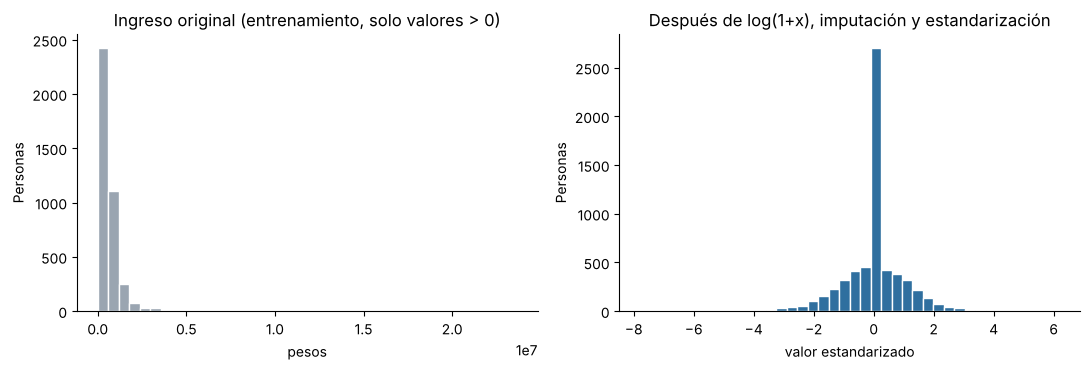

In [9]:
# Efecto de la transformación del ingreso: distribución original (con dato) y después de log + escalado
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].hist(X_train["ingreso_resto_hogar_pc"].dropna(), bins=40, color="#9aa5b1", edgecolor="white")
ejes[0].set_title("Ingreso original (entrenamiento, solo valores > 0)")
ejes[0].set_xlabel("pesos")
ejes[1].hist(X_train_esc["ingreso_resto_hogar_pc"], bins=40, color="#2f6f9f", edgecolor="white")
ejes[1].set_title("Después de log(1+x), imputación y estandarización")
ejes[1].set_xlabel("valor estandarizado")
for eje in ejes:
    eje.set_ylabel("Personas")
    eje.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/prep_transformacion_ingreso.png", dpi=110)

**Lectura:**

- No quedan faltantes en ninguna de las dos matrices.
- En entrenamiento, las numéricas escaladas tienen media 0 y desvío 1, como se espera de la estandarización. En prueba los valores son cercanos pero no exactos, lo cual es correcto: se representan con la referencia del entrenamiento.
- Después del logaritmo, el ingreso deja de tener una cola tan larga y su distribución es casi simétrica. Se ve un pico en el centro: es la mediana imputada, donde quedan los hogares sin respuesta y los de ingreso 0. Esto muestra el límite de la imputación (todos esos casos reciben el mismo valor) y es la razón por la que se conservan los dos indicadores.

In [10]:
# Vista de las primeras filas de la matriz escalada (ya lista para un modelo)
X_train_esc.head()

,edad,personas_hogar,menores_10_hogar,personas_por_ambiente,ingreso_resto_hogar_pc,sexo_mujer,ingresos_sin_respuesta,ingreso_resto_cero,parentesco_jefe_conyuge,parentesco_jefe_hijo,parentesco_jefe_jefe,parentesco_jefe_nieto,parentesco_jefe_no_familiar,parentesco_jefe_otro_familiar,estado_civil_separado_divorciado_viudo,estado_civil_soltero,estado_civil_unido_o_casado,cobertura_salud_obra_social_o_prepaga,cobertura_salud_sin_cobertura,cobertura_salud_solo_plan_publico,lugar_nacimiento_esta_localidad,lugar_nacimiento_otra_localidad_provincia,lugar_nacimiento_otra_provincia,lugar_nacimiento_otro_pais,condicion_actividad_desocupado,condicion_actividad_inactivo,condicion_actividad_ocupado,tipo_vivienda_casa,tipo_vivienda_departamento,tipo_vivienda_otro,tenencia_vivienda_inquilino,tenencia_vivienda_otra_situacion,tenencia_vivienda_propietario,jefe_nivel_educativo_no_aplica,jefe_nivel_educativo_primaria_completa,jefe_nivel_educativo_secundaria_completa,jefe_nivel_educativo_secundaria_incompleta,jefe_nivel_educativo_sin_instruccion_o_primaria_incompleta,jefe_nivel_educativo_superior_completo,jefe_nivel_educativo_superior_incompleto,jefe_sexo_mujer,jefe_sexo_no_aplica,jefe_sexo_varon,jefe_condicion_actividad_desocupado,jefe_condicion_actividad_inactivo,jefe_condicion_actividad_no_aplica,jefe_condicion_actividad_ocupado,region_cuyo,region_gran_buenos_aires,region_noreste,region_noroeste,region_pampeana,region_patagonia
0,0.397095,-0.526934,-0.433107,-0.817432,0.638239,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.397095,-0.526934,-0.433107,-0.475704,0.018493,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.436908,0.024216,-0.433107,-0.020068,0.375252,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.122812,0.575365,-0.433107,0.435568,0.018493,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.682532,0.024216,-0.433107,-0.475704,-0.055171,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [11]:
# Las columnas one-hot quedan como indicadores 0/1, sin escalar
onehot = [c for c in columnas_salida if c not in escaladas + BINARIAS]
print(f"Columnas one-hot: {len(onehot)}")
print("Valores presentes en las columnas one-hot:", sorted(np.unique(X_train_esc[onehot].values)))

Columnas one-hot: 45
Valores presentes en las columnas one-hot: [np.float64(0.0), np.float64(1.0)]


## 6. Guardado de las matrices preparadas

Se guardan en `data/processed/` dos archivos, uno por variante. Cada fila es un joven e incluye la columna `particion` (entrenamiento / prueba) y la variable objetivo, para que la etapa de modelado use exactamente esta misma separación.

In [12]:
def guardar(X_tr, X_te, ruta):
    tabla = pd.concat([
        X_tr.assign(particion="entrenamiento", asiste_superior=y_train),
        X_te.assign(particion="prueba", asiste_superior=y_test),
    ])
    tabla = tabla[["particion", "asiste_superior"] + list(X_tr.columns)]
    tabla.to_csv(ruta, index=False)
    print(f"{ruta}: {tabla.shape[0]:,} filas × {tabla.shape[1]} columnas")

guardar(X_train_esc, X_test_esc, "../data/processed/matriz_preparada_escalada.csv")
guardar(X_train_sin, X_test_sin, "../data/processed/matriz_preparada_sin_escalar.csv")

../data/processed/matriz_preparada_escalada.csv: 9,665 filas × 55 columnas
../data/processed/matriz_preparada_sin_escalar.csv: 9,665 filas × 55 columnas


## Resumen del preprocesamiento

| Paso | Decisión |
|---|---|
| Variables excluidas de X | Identificación, ponderador, trimestre, `es_jefe_o_conyuge` (contenida en parentesco) y `aglomerado` (contenida en región) |
| Recodificación (antes de separar) | Códigos → etiquetas; categorías poco frecuentes agrupadas; Ns/Nr y sin entrevista → faltante; datos del jefe/a de jóvenes jefe/a o cónyuge → "no aplica" |
| Partición | Temporal: entrenamiento 2T–4T 2025 (6.168), prueba 1T 2026 (3.497); sin personas compartidas |
| Numéricas | Mediana + estandarización |
| Ingreso | Ingreso = 0 → indicador `ingreso_resto_cero` y monto vacío; log(1+x) + mediana + estandarización; se conservan los indicadores de no respuesta y de ingreso 0 |
| Nominales | Moda + one-hot (sin orden impuesto) |
| Ajuste | Todos los parámetros aprendidos solo con entrenamiento |
| Salidas | `matriz_preparada_escalada.csv` (logística, KNN, SVM) y `matriz_preparada_sin_escalar.csv` (árboles) |

La variable `condicion_actividad` se conserva en las matrices, señalada como "zona gris" (puede ser en parte consecuencia de estudiar).